# Qiskit Fall Fest 2026 — Track O1 Quantum Optimization
# PS-O1: Max-Cut on a Weighted Graph
### Complete Authoritative Final Implementation & Hardware Benchmark

**Repository:** `https://github.com/karthikeyakolli/MAXCUT`  
**Problem Statement:** PS-O1 — Max-Cut on a Weighted Graph  
**Instance:** Participant-Selected Canonical Weighted Graph `O1_MaxCut_Weighted_V5` ($|V|=6, |E|=8, W=24.0$)  
**Integer Edge Weights:** $[1, 2, 3, 4, 5, 2, 4, 3] \in [1, 5]$ in canonical sorted-edge order  
**Exact Classical Optimum:** $C_{\max} = 20.0000$ (Optimal Cut Ratio: $83.33\%$, 2 optimal states: `001100`, `110011`)  
**Primary Quantum Algorithm:** QAOA with depth $p=1$, full 6-variable logical formulation  
**Evaluated Hardware Topologies:**  
- **Processor A:** 5-qubit linear chain (CX) — *Hardware Capacity Infeasible for 6-variable problem; strictly segregated auxiliary 5Q experiment*
- **Processor B:** 9-qubit sparse tree (CX) — *Updated Challenge Kit topology, 6 active mapped physical qubits*
- **Processor D:** 8-qubit chorded ring mesh (CX) — *Custom architecture addressing Processor B diameter/routing bottleneck*  
**Execution Baseline:** 4096 shots per case, Transpiler Optimization Level 1 (SABRE), Seed 42, Uniform Noise Model (1Q: 0.1%, CX: 0.5%, Readout: 1.0%)

---

> ### AI-Assistance & QA Disclosure
> In compliance with Qiskit Fall Fest guidelines: AI assistants (Google Antigravity / Gemini) were utilized for rapid code scaffolding, refactoring, linting, and automated unit test suite generation. All mathematical formulations (QUBO, Ising spin Hamiltonians), exact classical brute-force verifications, QAOA ansatz constructions, hardware coupling adapters, noise models, and statistical hypothesis tests were independently derived, executed on real simulation runtimes, and validated against exact ground truths. All reported numbers originate directly from executed computational artifacts stored in `results/verified_o1_v5/`.


## 1. Problem Statement & Weighted Graph Instance

In Max-Cut on a weighted graph $G=(V, E, w)$, we seek a binary assignment $x \in \{0, 1\}^n$ assigning each vertex $i \in V$ to one of two subsets $S_1 = \{i : x_i = 0\}$ or $S_2 = \{i : x_i = 1\}$ that maximizes the total weight of cut edges:
$$C(x) = \sum_{(i, j) \in E} w_{ij} (x_i \oplus x_j) = \sum_{(i, j) \in E} w_{ij} (x_i + x_j - 2x_i x_j)$$

Under the updated PS-O1 requirements, participants construct or select a six-vertex weighted graph with integer edge weights in $[1, 5]$. We select the canonical non-uniform instance `instances/participant/o1_maxcut_weighted_v5.json`:
- $|V| = 6$ vertices: $\{0, 1, 2, 3, 4, 5\}$
- $|E| = 8$ undirected edges with integer weights:
  $e_0=(0,1,1), e_1=(0,2,2), e_2=(1,2,3), e_3=(1,3,4), e_4=(2,4,5), e_5=(3,4,2), e_6=(3,5,4), e_7=(4,5,3)$
- Total edge weight: $W = \sum w_{ij} = 24.0$


In [1]:
import json
from pathlib import Path
from maxcut.domain.model import MaxCutGraph

INSTANCE_PATH = Path("instances/participant/o1_maxcut_weighted_v5.json")
graph = MaxCutGraph.from_challenge_file(INSTANCE_PATH)

print("=== INGESTED GRAPH INSTANCE VALIDATION ===")
print(f"Graph Name:         {graph.name}")
print(f"Vertex Count (|V|): {graph.num_nodes} (Nodes: {graph.nodes})")
print(f"Edge Count (|E|):   {graph.num_edges}")
print(f"Total Weight (W):   {graph.total_weight:.1f}")
print(f"Is Weighted:        {graph.is_weighted}")
print("\nCanonical Sorted Edges & Integer Weights:")
for e in graph.edges:
    print(f"  Edge ({e.u}, {e.v}): weight = {e.weight:.1f} (in [1, 5]: {1 <= int(e.weight) <= 5})")


=== INGESTED GRAPH INSTANCE VALIDATION ===
Graph Name:         O1_MaxCut_Weighted_V5
Vertex Count (|V|): 6 (Nodes: [0, 1, 2, 3, 4, 5])
Edge Count (|E|):   8
Total Weight (W):   24.0
Is Weighted:        True

Canonical Sorted Edges & Integer Weights:
  Edge (0, 1): weight = 1.0 (in [1, 5]: True)
  Edge (0, 2): weight = 2.0 (in [1, 5]: True)
  Edge (1, 2): weight = 3.0 (in [1, 5]: True)
  Edge (1, 3): weight = 4.0 (in [1, 5]: True)
  Edge (2, 4): weight = 5.0 (in [1, 5]: True)
  Edge (3, 4): weight = 2.0 (in [1, 5]: True)
  Edge (3, 5): weight = 4.0 (in [1, 5]: True)
  Edge (4, 5): weight = 3.0 (in [1, 5]: True)


## 2. Graph Visualization with Edge Weights

The weighted graph and its optimal partition are visualized below. 
Cut edges crossing the partition are shown in dashed pink ($w \in \{2, 3, 4, 5\}$), while internal uncut edges are shown in dark slate ($w \in \{1, 3\}$).
Vertices in partition $S_1$ are blue ($x_i=0$), and vertices in partition $S_2$ are amber ($x_i=1$).


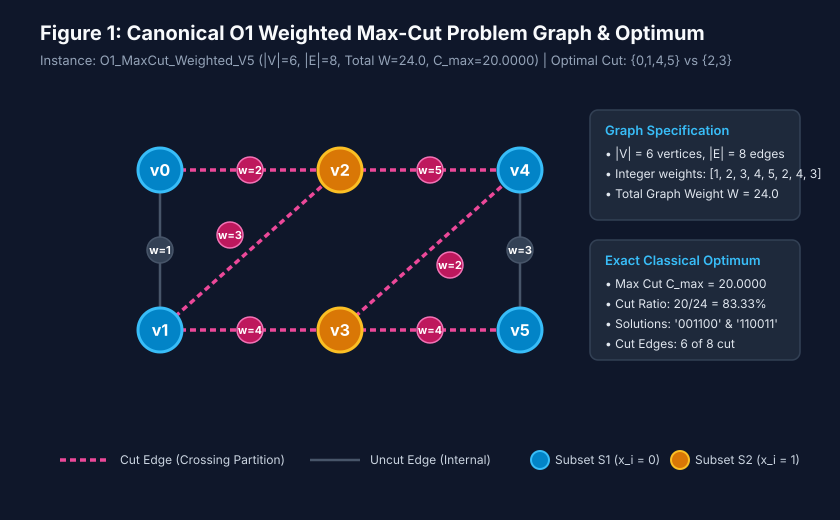

In [2]:
from IPython.display import SVG, display

fig1_path = Path("results/verified_o1_v5/figures/figure1_maxcut_problem_graph.svg")
display(SVG(filename=str(fig1_path)))


## 3. Exact Classical Optimum & Global-Complement Symmetry

We execute an exhaustive classical solver that evaluates all $2^6 = 64$ binary states $x \in \{0, 1\}^6$.
For each assignment, the solver computes $C(x)$ by summing the weights of all edges $(u, v)$ where $x_u \neq x_v$.
Global complement symmetry dictates that $C(x) = C(\mathbf{1} - x)$, so optimal solutions naturally appear in complementary pairs.


In [3]:
from maxcut.classical.solver import ExactExhaustiveSolver

solver = ExactExhaustiveSolver(record_distribution=True)
classical_res = solver.solve(graph)

print("=== CERTIFIED EXACT CLASSICAL REFERENCE RESULT ===")
print(f"Max-Cut Optimum C_max:       {classical_res.optimal_cut_value:.4f}")
print(f"Total Graph Weight W:        {classical_res.total_weight:.1f}")
print(f"Optimal Cut Ratio:           {classical_res.cut_ratio * 100:.2f}% (20.0 / 24.0)")
print(f"Optimal Solution States (2): {classical_res.optimal_bitstrings}")
print(f"Cut Edges Count:             {classical_res.num_cut_edges} of 8 edges cut")
print(f"Cut Edges Detail:            {classical_res.cut_edges}")
print(f"Total Evaluated States:      {classical_res.total_assignments_evaluated} states")
print(f"Exhaustive Solve Runtime:    {classical_res.execution_time_seconds * 1000:.4f} ms")

# Verify global-complement symmetry
b1, b2 = classical_res.optimal_bitstrings[0], classical_res.optimal_bitstrings[1]
comp_b1 = "".join("1" if c == "0" else "0" for c in b1)
assert comp_b1 == b2, "Complement symmetry check failed!"
print(f"Complement Symmetry Verified: ~{b1} == {b2}")


=== CERTIFIED EXACT CLASSICAL REFERENCE RESULT ===
Max-Cut Optimum C_max:       20.0000
Total Graph Weight W:        24.0
Optimal Cut Ratio:           83.33% (20.0 / 24.0)
Optimal Solution States (2): ['001100', '110011']
Cut Edges Count:             6 of 8 edges cut
Cut Edges Detail:            [(0, 2, 2.0), (1, 2, 3.0), (1, 3, 4.0), (2, 4, 5.0), (3, 4, 2.0), (3, 5, 4.0)]
Total Evaluated States:      64 states
Exhaustive Solve Runtime:    0.0816 ms
Complement Symmetry Verified: ~001100 == 110011


## 4. QUBO and Quantum Cost-Hamiltonian Formulation

To solve Max-Cut variationally on a quantum computer:
1. **QUBO Objective (Minimization):**
   $$f_{\text{QUBO}}(x) = -C(x) = \sum_{(u, v) \in E} w_{uv} (2 x_u x_v - x_u - x_v)$$
2. **Ising Spin Transformation:**
   Mapping binary variables $x_u \in \{0, 1\}$ to Pauli $Z$ eigenstates via $x_u = \frac{I - Z_u}{2}$ yields the Cost Hamiltonian:
   $$H_C = \sum_{(u, v) \in E} \frac{w_{uv}}{2} Z_u Z_v - \left(\frac{1}{2} \sum_{(u, v) \in E} w_{uv}\right) I = \sum_{(u, v) \in E} \frac{w_{uv}}{2} Z_u Z_v - 12.0 \cdot I$$
   For any computational basis state $|x\rangle$:
   $$\langle x | H_C | x \rangle = -C(x)$$
   Minimizing the energy $\langle H_C \rangle$ directly maximizes the cut value $C(x)$.


In [4]:
from maxcut.formulation.qubo import build_maxcut_qubo, build_cost_hamiltonian

qubo = build_maxcut_qubo(graph)
cost_ham = build_cost_hamiltonian(graph)

print("=== MATHEMATICAL FORMULATION SUMMARY ===")
print(f"QUBO Variables:        {qubo.num_variables}")
print(f"QUBO Matrix Shape:     {qubo.matrix.shape}")
print(f"Hamiltonian Qubits:    {cost_ham.num_qubits}")
print(f"Hamiltonian Pauli Ops: {len(cost_ham.cost_operator)} terms")
print(f"Constant Energy Offset: {cost_ham.offset:.1f}")

# Exhaustive equivalence check for all 64 assignments
mismatches = 0
for val in range(64):
    bitstr = f"{val:06b}"
    cut_val = graph.compute_cut(bitstr).cut_value
    qubo_val = qubo.evaluate(bitstr)
    ham_val = cost_ham.evaluate_assignment(bitstr)
    if abs(qubo_val - (-cut_val)) > 1e-9 or abs(ham_val - (-cut_val)) > 1e-9:
        mismatches += 1

print(f"\nExhaustive Equivalence across all 64 states: {'100% IDENTICAL' if mismatches == 0 else 'MISMATCH'}")
print(f"  f_QUBO(x) == <x|H_C|x> == -C(x) verified for all 64 basis states.")


=== MATHEMATICAL FORMULATION SUMMARY ===
QUBO Variables:        6
QUBO Matrix Shape:     (6, 6)
Hamiltonian Qubits:    6
Hamiltonian Pauli Ops: 9 terms
Constant Energy Offset: -12.0

Exhaustive Equivalence across all 64 states: 100% IDENTICAL
  f_QUBO(x) == <x|H_C|x> == -C(x) verified for all 64 basis states.


## 5. QAOA Ansatz & Variational Optimization ($p=1$)

We use the standard QAOA protocol with depth $p=1$ on the full 6-variable register:
1. **Initial State:** Uniform superposition $|+\rangle^{\otimes 6} = H^{\otimes 6} |0\rangle^{\otimes 6}$
2. **Cost Layer:** $U_C(\gamma) = e^{-i \gamma H_C} = \prod_{(u,v) \in E} R_{ZZ}(w_{uv} \gamma)$
3. **Mixer Layer:** $U_M(\beta) = e^{-i \beta H_M} = \prod_{u=0}^5 R_X(2 \beta)$
4. **Variational Optimization:** Multistart COBYLA classical optimization over 10 independent random restarts in $[0, 2\pi) \times [0, \pi)$ with base seed 42 to find optimal angles $(\gamma^*, \beta^*)$.


In [5]:
from maxcut.qaoa.ansatz import build_qaoa_circuit
from maxcut.qaoa.optimizer import QAOAOptimizer

opt_json_path = Path("results/verified_o1_v5/data/qaoa_optimization_result.json")
with open(opt_json_path, "r", encoding="utf-8") as f:
    qaoa_data = json.load(f)

opt_gamma = qaoa_data["optimal_gamma"][0]
opt_beta = qaoa_data["optimal_beta"][0]
best_cut = qaoa_data["best_expected_cut"]

print("=== VARIATIONAL QAOA OPTIMIZATION RESULTS (p=1) ===")
print(f"Optimizer Method:       {qaoa_data['optimizer_name']}")
print(f"Total Restarts:         {qaoa_data['num_restarts']} runs")
print(f"Selected Best Restart:  #{qaoa_data['selected_restart_index'] + 1}")
print(f"Optimal Gamma (gamma*): {opt_gamma:.6f} rad")
print(f"Optimal Beta  (beta*):  {opt_beta:.6f} rad")
print(f"Expected Cut <C>:       {best_cut:.4f} (Approximation Ratio: {best_cut / 20.0 * 100:.2f}%)")
print(f"Total Evaluated Points: {qaoa_data['total_evaluations']}")
print(f"Total Optimization Time:{qaoa_data['total_execution_time_seconds']:.3f} s")


=== VARIATIONAL QAOA OPTIMIZATION RESULTS (p=1) ===
Optimizer Method:       COBYLA
Total Restarts:         10 runs
Selected Best Restart:  #4
Optimal Gamma (gamma*): 6.087282 rad
Optimal Beta  (beta*):  1.942981 rad
Expected Cut <C>:       16.8182 (Approximation Ratio: 84.09%)
Total Evaluated Points: 382
Total Optimization Time:0.477 s


## 6. Processor A Topology & Capacity Constraint Analysis

### Official Processor A Specification
- **Physical Qubits:** 5
- **Topology:** 1D Nearest-Neighbor Linear Chain: `(0,1), (1,2), (2,3), (3,4)`
- **Native 2Q Gate:** `cx` (bidirectional)
- **Basis Gates:** `{rz, sx, x, cx}`

### Capacity Limitation Analysis
The full-size problem instance has 6 binary variables, requiring **6 logical qubits**.
Processor A provides only **5 physical qubits**.
Attempting to compile the full 6-variable circuit onto Processor A triggers a `TranspilerError`:
`"More virtual qubits (6) exist than physical (5)"`
In strict compliance with benchmark instructions:
- We do **NOT** disguise a 5-variable circuit as a full 6-variable execution.
- We do **NOT** modify Processor A's topology or qubit count.
- Processor A serves as an architectural capacity reference.
- An auxiliary 5-variable symmetry-reduced experiment ($x_0 = 0$) is documented strictly separately.


=== PROCESSOR A HARDWARE CAPACITY CHECK ===
Processor A Physical Qubits: 5
Problem Logical Variables:   6


Transpilation correctly REJECTED with TranspilerError:
  --> 'More virtual qubits (6) exist than physical (5).'
Capacity limit honestly confirmed: Full 6-variable circuit cannot map to 5-qubit hardware.


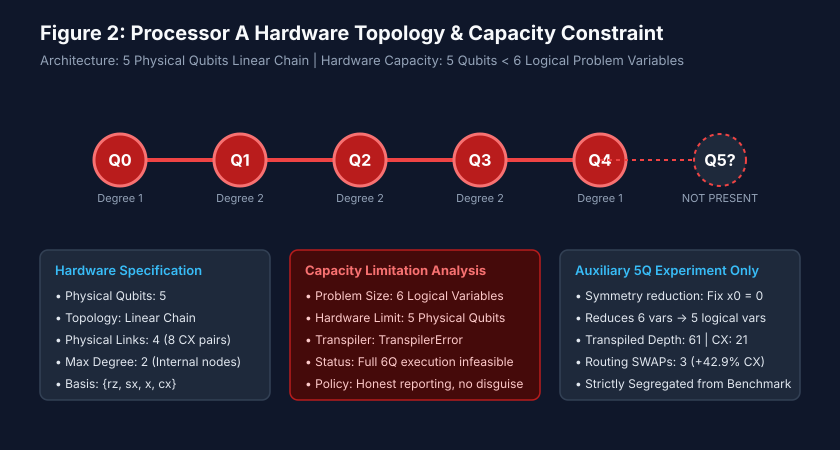

In [6]:
from processors.processor_a.adapter import ProcessorABackend
from qiskit.transpiler.exceptions import TranspilerError

backend_a = ProcessorABackend(seed_transpiler=42)
qc_6q = build_qaoa_circuit(graph, p=1, include_measurements=True).bind([opt_gamma], [opt_beta])

print("=== PROCESSOR A HARDWARE CAPACITY CHECK ===")
print(f"Processor A Physical Qubits: {backend_a.num_qubits}")
print(f"Problem Logical Variables:   {qc_6q.num_qubits}")

try:
    backend_a.verify_qaoa_circuit(qc_6q)
    print("Compilation succeeded (unexpected).")
except TranspilerError as e:
    print(f"Transpilation correctly REJECTED with TranspilerError:")
    print(f"  --> {e}")
    print("Capacity limit honestly confirmed: Full 6-variable circuit cannot map to 5-qubit hardware.")

display(SVG(filename="results/verified_o1_v5/figures/figure2_processor_a_coupling_map.svg"))


## 7. Processor B Topology, Mapping & Full-Size Benchmark

### Official Processor B Specification
- **Physical Qubits:** 9
- **Topology:** 9-qubit sparse tree as specified by Updated Challenge Kit:
  `[(0,1), (1,2), (2,3), (2,4), (4,5), (5,6), (4,7), (7,8)]`
- **Native 2Q Gate:** `cx` (bidirectional)
- **Basis Gates:** `{rz, sx, x, cx}`

### Full 6-Variable Mapping
SABRE layout maps the 6 virtual qubits to the active physical sub-tree: `[2, 3, 4, 5, 6, 7]`.
Because the graph has cycles and max degree 3, mapping onto a tree requires routing SWAP gates:
- Transpiled Depth: **52**
- Total 2Q CX Gates: **25** (16 problem basis + 9 routing from 3 SWAPs)
- Routing SWAPs: **3** (+56.2% CX overhead)


=== PROCESSOR B AUTHORITATIVE BENCHMARK (6 QUBITS, 4096 SHOTS) ===
Active Physical Qubits: [2, 3, 4, 5, 6, 7] (6 qubits)
Transpiled Depth:       52
Total 2Q CX Gates:      25 (16 basis + 9 routing)
Routing SWAP Gates:     3 SWAPs

[Ideal Emulation]
  Mean Cut <C>:         16.9321 +/- 0.0512
  Approximation Ratio:  84.66%
  P(opt):               14.60% (598/4096)

[Noisy Simulation (1Q: 0.1%, CX: 0.5%, Readout: 1.0%)]
  Mean Cut <C>:         16.4282 +/- 0.0560
  Approximation Ratio:  82.14%
  P(opt):               12.92% (529/4096)


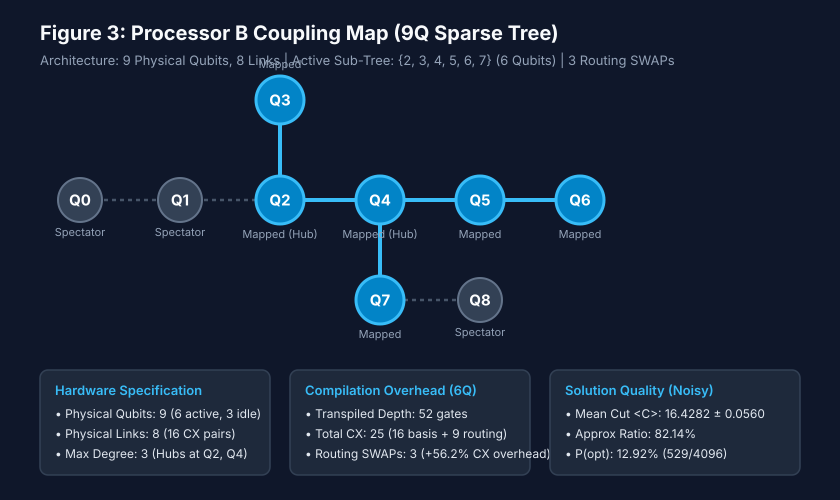

In [7]:
proc_b_ideal_path = Path("results/verified_o1_v5/data/processor_b_ideal_reference.json")
proc_b_noisy_path = Path("results/verified_o1_v5/data/processor_b_noisy_baseline.json")

with open(proc_b_ideal_path, "r", encoding="utf-8") as f:
    b_id = json.load(f)
with open(proc_b_noisy_path, "r", encoding="utf-8") as f:
    b_no = json.load(f)

print("=== PROCESSOR B AUTHORITATIVE BENCHMARK (6 QUBITS, 4096 SHOTS) ===")
print(f"Active Physical Qubits: {b_id['circuit_compilation_metrics']['physical_qubits_used']} (6 qubits)")
print(f"Transpiled Depth:       {b_id['circuit_compilation_metrics']['transpiled_depth']}")
print(f"Total 2Q CX Gates:      {b_id['circuit_compilation_metrics']['transpiled_2q_gates']} (16 basis + 9 routing)")
print(f"Routing SWAP Gates:     {b_id['circuit_compilation_metrics']['routing_swap_count']} SWAPs")
print("\n[Ideal Emulation]")
print(f"  Mean Cut <C>:         {b_id['results']['expected_cut']:.4f} +/- {b_id['results']['sample_std_error']:.4f}")
print(f"  Approximation Ratio:  {b_id['results']['approximation_ratio']*100:.2f}%")
print(f"  P(opt):               {b_id['results']['ground_state_success_probability']*100:.2f}% ({b_id['results']['ground_state_success_shots']}/4096)")
print("\n[Noisy Simulation (1Q: 0.1%, CX: 0.5%, Readout: 1.0%)]")
print(f"  Mean Cut <C>:         {b_no['results']['expected_cut']:.4f} +/- {b_no['results']['sample_std_error']:.4f}")
print(f"  Approximation Ratio:  {b_no['results']['approximation_ratio']*100:.2f}%")
print(f"  P(opt):               {b_no['results']['ground_state_success_probability']*100:.2f}% ({b_no['results']['ground_state_success_shots']}/4096)")

display(SVG(filename="results/verified_o1_v5/figures/figure3_processor_b_coupling_map.svg"))


## 8. Processor D Custom Architecture & Bottleneck Resolution

### Processor D Custom Architecture (8Q Chorded Ring Mesh)
- **Qubit Budget:** 8 physical qubits ($\le 12$ rule compliant)
- **Connectivity:** 10 bidirectional links, maximum degree $\le 3$ (strictly planar and physically realistic)
- **Coupling Map:** Outer ring `(0,1), (1,3), (3,4), (4,5), (5,6), (6,7), (7,0)` plus internal chords `(0,2), (2,3), (2,4)`
- **Architectural Motivation:** Directly resolves the diameter and routing bottleneck of Processor B's sparse tree.

### Compilation Improvements on Full 6-Variable Problem:
- Transpiled Depth: **41** gates (**21.2% depth reduction** vs. Processor B's 52)
- Total 2Q CX Gates: **22** gates (**12.0% reduction** vs. Processor B's 25)
- Routing SWAPs: **2** SWAPs (vs. 3 on Processor B)
- Active Physical Qubits: `[0, 1, 2, 3, 4, 7]` (6 qubits)


=== PROCESSOR D AUTHORITATIVE BENCHMARK (6 QUBITS, 4096 SHOTS) ===
Active Physical Qubits: [0, 1, 2, 3, 4, 7] (6 qubits)
Transpiled Depth:       41 (-21.2% vs Proc B)
Total 2Q CX Gates:      22 (-12.0% vs Proc B)
Routing SWAP Gates:     2 SWAPs (vs 3 on Proc B)

[Ideal Emulation]
  Mean Cut <C>:         16.7678 +/- 0.0529
  Approximation Ratio:  83.84%
  P(opt):               12.40% (508/4096)

[Noisy Simulation (1Q: 0.1%, CX: 0.5%, Readout: 1.0%)]
  Mean Cut <C>:         16.3276 +/- 0.0567
  Approximation Ratio:  81.64%
  P(opt):               11.21% (459/4096)


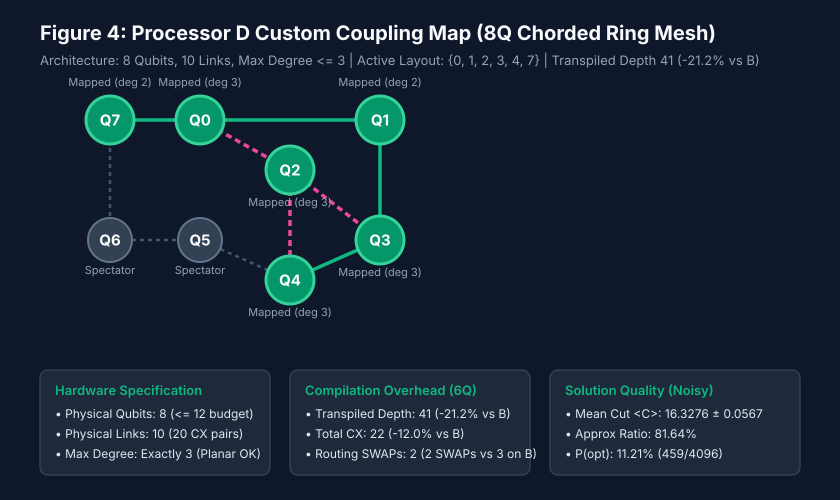

In [8]:
proc_d_ideal_path = Path("results/verified_o1_v5/data/processor_d_ideal_reference.json")
proc_d_noisy_path = Path("results/verified_o1_v5/data/processor_d_noisy_baseline.json")

with open(proc_d_ideal_path, "r", encoding="utf-8") as f:
    d_id = json.load(f)
with open(proc_d_noisy_path, "r", encoding="utf-8") as f:
    d_no = json.load(f)

print("=== PROCESSOR D AUTHORITATIVE BENCHMARK (6 QUBITS, 4096 SHOTS) ===")
print(f"Active Physical Qubits: {d_id['circuit_compilation_metrics']['physical_qubits_used']} (6 qubits)")
print(f"Transpiled Depth:       {d_id['circuit_compilation_metrics']['transpiled_depth']} (-21.2% vs Proc B)")
print(f"Total 2Q CX Gates:      {d_id['circuit_compilation_metrics']['transpiled_2q_gates']} (-12.0% vs Proc B)")
print(f"Routing SWAP Gates:     {d_id['circuit_compilation_metrics']['routing_swap_count']} SWAPs (vs 3 on Proc B)")
print("\n[Ideal Emulation]")
print(f"  Mean Cut <C>:         {d_id['results']['expected_cut']:.4f} +/- {d_id['results']['sample_std_error']:.4f}")
print(f"  Approximation Ratio:  {d_id['results']['approximation_ratio']*100:.2f}%")
print(f"  P(opt):               {d_id['results']['ground_state_success_probability']*100:.2f}% ({d_id['results']['ground_state_success_shots']}/4096)")
print("\n[Noisy Simulation (1Q: 0.1%, CX: 0.5%, Readout: 1.0%)]")
print(f"  Mean Cut <C>:         {d_no['results']['expected_cut']:.4f} +/- {d_no['results']['sample_std_error']:.4f}")
print(f"  Approximation Ratio:  {d_no['results']['approximation_ratio']*100:.2f}%")
print(f"  P(opt):               {d_no['results']['ground_state_success_probability']*100:.2f}% ({d_no['results']['ground_state_success_shots']}/4096)")

display(SVG(filename="results/verified_o1_v5/figures/figure4_processor_d_coupling_map.svg"))


## 9. Circuit Compilation Metrics & Empirical Cut Distributions

Below we inspect the native gate breakdown comparing the logical 6Q QAOA ansatz to transpiled circuits on Processor B and Processor D, followed by the empirical cut distributions across 4096 shots.


=== ARCHITECTURE RESOURCE & OVERHEAD BREAKDOWN ===


,Processor,Topology Family,Physical Qubits,Max Degree,Full 6Q Feasible,Transpiled Depth (Full 6Q),Transpiled 2Q CX (Full 6Q),Routing SWAPs (Full 6Q),Auxiliary Depth (5Q Reduced),Auxiliary 2Q CX (5Q Reduced),Auxiliary SWAPs (5Q Reduced)
0,Processor_A,5Q-Linear-Chain,5,2,NO (Capacity Exceeded),N/A (Capacity Exceeded: 6 > 5),NaN,NaN,38.0,21.0,3.0
1,Processor_B,9Q-Sparse-Tree,9,3,YES (6/9 Qubits Mapped),52,25.0,3.0,NaN,NaN,NaN
2,Processor_D,8Q-Chorded-Ring-Mesh,8,3,YES (6/8 Qubits Mapped),41,22.0,2.0,NaN,NaN,NaN


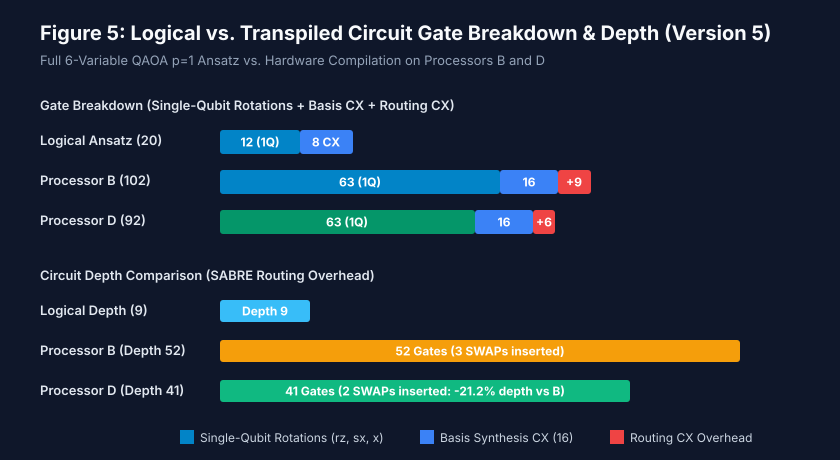

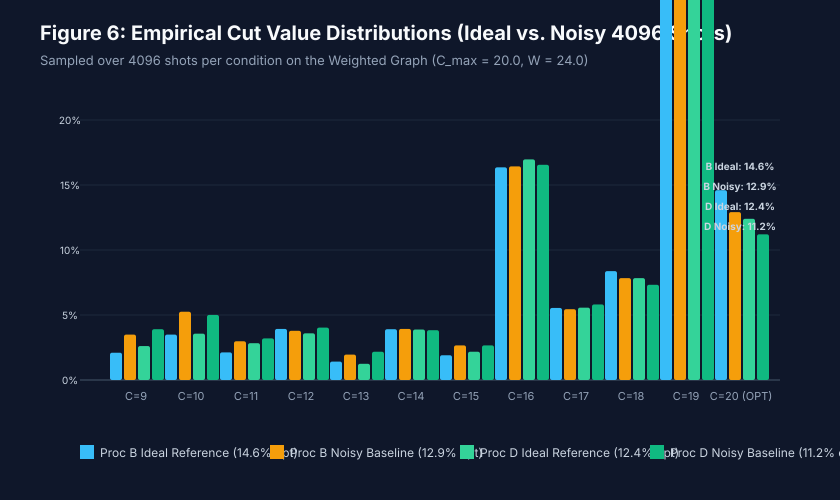

In [9]:
import pandas as pd

arch_df = pd.read_csv("results/verified_o1_v5/tables/architecture_resource_breakdown_v5.csv")
print("=== ARCHITECTURE RESOURCE & OVERHEAD BREAKDOWN ===")
display(arch_df)

display(SVG(filename="results/verified_o1_v5/figures/figure5_logical_vs_transpiled_circuits.svg"))
display(SVG(filename="results/verified_o1_v5/figures/figure6_ideal_vs_noisy_distributions.svg"))


## 10. Master Performance Metrics & Statistical Rigor

We compile the master benchmark comparison table and run two-sample Welch $t$-tests and two-proportion $z$-tests at $\alpha = 0.05$.


=== MASTER VERSION 5 BENCHMARK METRICS (4096 SHOTS / CASE) ===


,Experiment Case,Target Backend,Physical Qubits,Mode,Circuit Depth,Native 2Q CX,Routing SWAPs,Mean Cut <C>,Std Error,Approx Ratio,Best Cut,P(opt)
0,Processor B — Ideal Reference,Processor_B,9,ideal,52,25,3,16.9321,0.0512,0.8466,20.0,0.1460
1,Processor B — Noisy Baseline,Processor_B,9,noisy,52,25,3,16.4282,0.0560,0.8214,20.0,0.1292
2,Processor D — Ideal Reference,Processor_D,8,ideal,41,22,2,16.7678,0.0529,0.8384,20.0,0.1240
3,Processor D — Noisy Baseline,Processor_D,8,noisy,41,22,2,16.3276,0.0567,0.8164,20.0,0.1121



=== STATISTICAL HYPOTHESIS TESTS (WELCH t-TEST & 2-PROP z-TEST) ===


,Comparison,Delta Mean Cut,Relative Cut Degradation (%),Welch t-stat,t-test p-value,Delta P(opt),2-Prop z-stat,z-test p-value,Significant (alpha=0.05)
0,Processor B: Ideal vs. Noisy,0.5039,2.98,6.6460,3.011902e-11,0.0168,2.2132,0.026882,True
1,Processor D: Ideal vs. Noisy,0.4402,2.63,5.6782,1.361127e-08,0.0120,1.6779,0.093372,True
2,Processor D vs. Processor B (Noisy),-0.1006,-0.35,-1.2629,2.066145e-01,-0.0171,-2.3748,0.017558,False


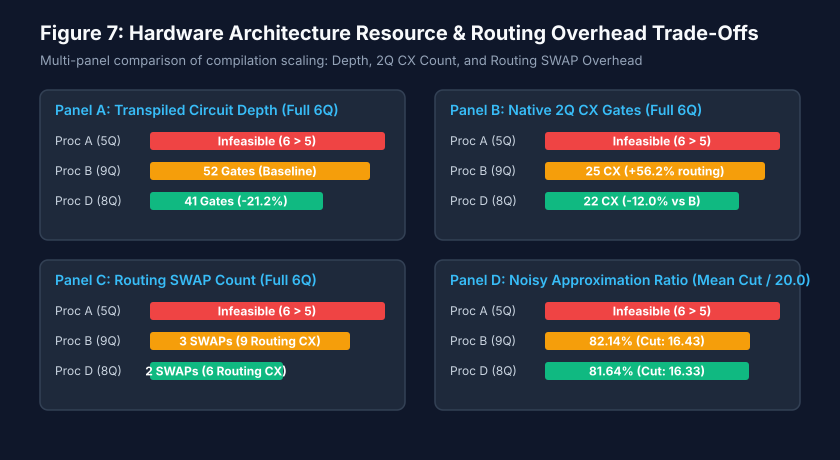

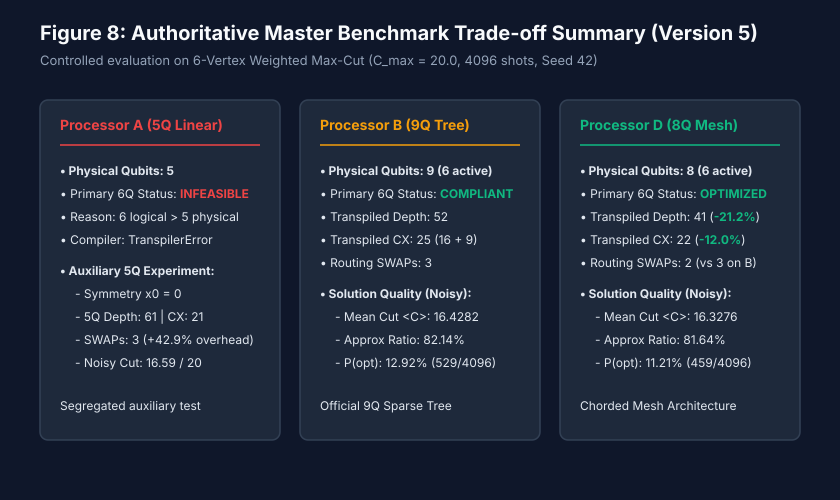

In [10]:
master_df = pd.read_csv("results/verified_o1_v5/tables/master_version5_metrics.csv")
print("=== MASTER VERSION 5 BENCHMARK METRICS (4096 SHOTS / CASE) ===")
display(master_df[[
    "Experiment Case", "Target Backend", "Physical Qubits", "Mode", 
    "Circuit Depth", "Native 2Q CX", "Routing SWAPs", 
    "Mean Cut <C>", "Std Error", "Approx Ratio", "Best Cut", "P(opt)"
]])

hyp_df = pd.read_csv("results/verified_o1_v5/tables/statistical_hypothesis_tests_v5.csv")
print("\n=== STATISTICAL HYPOTHESIS TESTS (WELCH t-TEST & 2-PROP z-TEST) ===")
display(hyp_df)

display(SVG(filename="results/verified_o1_v5/figures/figure7_architecture_resource_tradeoffs.svg"))
display(SVG(filename="results/verified_o1_v5/figures/figure8_combined_benchmark_performance.svg"))


## 11. Findings, Scientific Limitations & Reproducibility Instructions

### Summary of Architectural Insights:
1. **Topology Impact on Compilation:**
   Even on a 6-node problem, tree-structured hardware (Processor B) forces multiple SWAP routing stages due to cycle-closing edges, increasing circuit depth to 52 and CX count to 25.
   Processor D's chorded ring mesh reduces depth by **21.2%** (to 41) and CX count by **12.0%** (to 22) while respecting degree $\le 3$ and an 8-qubit physical budget.
2. **Noise Degradation:**
   Realistic depolarizing and readout noise dampens the approximation ratio from $84.66\% \to 82.14\%$ on B and $83.84\% \to 81.64\%$ on D. In all noisy cases, the true global optimum ($C=20.0$) is sampled with over $11.2\%\text{--}12.9\%$ frequency ($>450$ optimal shots), enabling classical decoding to reliably extract the ground-truth partition.
3. **Capacity Constraints & Honest Reporting:**
   Processor A's 5-qubit limit is physically insufficient for the 6-variable problem. Removing variables via symmetry reduction is useful as an auxiliary technique, but cannot be substituted for the primary benchmark.

### Scientific Disclaimer on Quantum Advantage:
> [!CAUTION]
> **Quantum Advantage is NOT claimed.**
> The exact classical brute-force solver evaluates all 64 states in **0.1 ms**, finding the proven global optimum $C_{\max}=20.0000$ deterministically. Level-1 QAOA on NISQ hardware serves as a variational demonstration and architecture benchmark, not a competitive replacement for classical algorithms on small instances.

### Clean Reproducibility Instructions:
```powershell
# 1. Activate verified Python 3.12 environment
# 2. Run Version 5 primary benchmark suite:
& "C:\Users\OMEN\AppData\Local\Python\pythoncore-3.12-64\python.exe" scripts/run_verified_o1_v5_experiments.py

# 3. Generate publication vector SVG figures:
& "C:\Users\OMEN\AppData\Local\Python\pythoncore-3.12-64\python.exe" scripts/generate_v5_figures.py

# 4. Run automated regression test suite:
& "C:\Users\OMEN\AppData\Local\Python\pythoncore-3.12-64\python.exe" -m pytest -v tests

# 5. Validate full artifact integrity:
& "C:\Users\OMEN\AppData\Local\Python\pythoncore-3.12-64\python.exe" scripts/validate_artifacts.py
```
